<style>
@page {
    size: A4;
    margin: 6mm 6mm 6mm 6mm;
}

body {
    font-family: "DejaVu Sans", "Arial", sans-serif;
    font-size: 10px;
    line-height: 1.15;
}

.jp-Notebook {
    max-width: 198mm;
    margin: 0 auto;
}

.jp-Cell {
    page-break-inside: avoid;
    break-inside: avoid;
    margin-top: 2px;
    margin-bottom: 2px;
}

h1, h2, h3, p {
    margin-top: 3px;
    margin-bottom: 3px;
}

pre, code {
    white-space: pre-wrap;
    word-break: break-word;
    overflow-wrap: anywhere;
    font-size: 9px;
}

table {
    width: 100%;
    table-layout: fixed;
    word-wrap: break-word;
}

img, svg, canvas {
    max-width: 100%;
    height: auto;
}

.output_area pre {
    white-space: pre-wrap;
    word-break: break-word;
    overflow-wrap: anywhere;
}
</style>

# T14: Проверка гипотезы о равенстве средних и график мощности

x̄ = -1.596667
ȳ = -2.600000
Δ = 0.928906
G: Δ >= 1.644854
Нет оснований отвергнуть H0


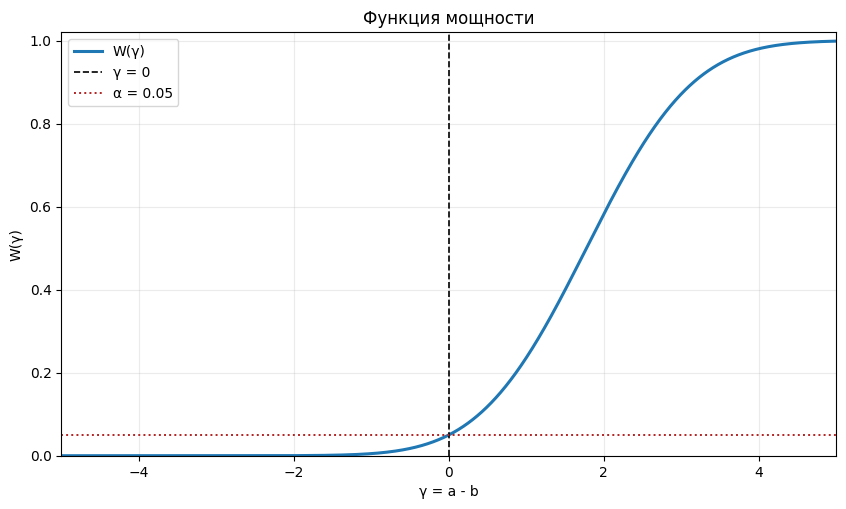

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st

x = np.array([-1.11, -6.10,  2.42])
y = np.array([-2.29, -2.91])

sigma_x2 = 2
sigma_y2 = 1

n = len(x)
m = len(y)
alpha = 0.05

x_bar = x.mean()
y_bar = y.mean()

s = np.sqrt(sigma_x2 / n + sigma_y2 / m)
Delta = (x_bar - y_bar) / s
u = st.norm.ppf(1 - alpha)

print(f'x̄ = {x_bar:.6f}')
print(f'ȳ = {y_bar:.6f}')
print(f'Δ = {Delta:.6f}')
print(f"G: Δ >= {u:.6f}")

if Delta >= u:
    print('Отвергаем H0, в пользу H1: a > b')
else:
    print('Нет оснований отвергнуть H0')

def W(gamma):
    return 1 - st.norm.cdf(u - gamma / s)

gamma_grid = np.linspace(-5, 5, 2000)
power = W(gamma_grid)

plt.figure(figsize=(10, 5.5))
plt.plot(gamma_grid, power, linewidth=2.2, label='W(γ)')
plt.axvline(0.0, color='black', linestyle='--', linewidth=1.2, label='γ = 0')
plt.axhline(alpha, color='firebrick', linestyle=':', linewidth=1.4, label='α = 0.05')
plt.xlim(gamma_grid[0], gamma_grid[-1])
plt.ylim(0, 1.02)
plt.xlabel('γ = a - b')
plt.ylabel('W(γ)')
plt.title('Функция мощности')
plt.grid(alpha=0.25)
plt.legend()
plt.show()
